In [1]:
%load_ext sql
%sql sqlite://
%config SqlMagic.style = '_DEPRECATED_DEFAULT'

## Продолжаем работу с таблицами

In [2]:
%%sql

DROP TABLE IF EXISTS Employees;

PRAGMA foreign_keys = OFF;

CREATE TABLE Employees(
    id int PRIMARY KEY,
    name varchar(20) NOT NULL,
    phone varchar(20),
    title varchar(20) NOT NULL,
    manager_id integer,
    FOREIGN KEY (manager_id) REFERENCES Employees(id)
);

 * sqlite://
Done.
Done.
Done.


[]

In [3]:
%%sql

--INSERT INTO Employees values  (1, 'Vasyugin', '+111', 'Director', NULL);
INSERT INTO Employees values  (2, 'Jones', '+112', 'Vice President', 1);
INSERT INTO Employees values  (3, 'Smith', '+113', 'Vice President', 1);
INSERT INTO Employees values (4, 'Velaskes', '+114', 'Developer', 2);
INSERT INTO Employees values (5, 'Simon', '+115', 'Analyst', 2);
INSERT INTO Employees values (6, 'Johnson', '+116', 'Engineer', 3);
INSERT INTO Employees values (7, 'Lee', '+117', 'Engineer', 3);

 * sqlite://
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.


[]

In [4]:
%%sql

PRAGMA foreign_key_check; -- проверка целостности

 * sqlite://
Done.


table,rowid,parent,fkid
Employees,1,Employees,0
Employees,2,Employees,0


In [5]:
%%sql

PRAGMA foreign_keys = ON;

 * sqlite://
Done.


[]

In [6]:
%%sql
DROP TABLE IF EXISTS Students;
DROP TABLE IF EXISTS Faculties;
DROP TABLE IF EXISTS Employees;

CREATE TABLE Faculties(
    id integer PRIMARY KEY,
    name varchar(50) NOT NULL,
    UNIQUE (name) -- уникальные значения
);

CREATE TABLE Students(
    id integer PRIMARY KEY,
    name varchar(50) NOT NULL,
    gpa decimal(2,2),
    faculty_id integer,
    FOREIGN KEY (faculty_id) REFERENCES Faculties(id)
);

CREATE TABLE Employees(
    id int PRIMARY KEY,
    name varchar(20) NOT NULL,
    phone varchar(20),
    title varchar(20) NOT NULL,
    manager_id integer,
    FOREIGN KEY (manager_id) REFERENCES Employees(id)
);

 * sqlite://
Done.
Done.
Done.
Done.
Done.
Done.


[]

In [7]:
%%sql
INSERT INTO Faculties values (1, 'IT');
INSERT INTO Faculties values (2, 'KIB');

INSERT INTO Students values (1, 'Sidorov', 3.0, 1);
INSERT INTO Students values (2, 'Petrov', 3.5, 2);
INSERT INTO Students values (3, 'Verikov', 4.0, 1);
INSERT INTO Students values (4, 'Smith', 4.2, 2);
INSERT INTO Students values (5, 'Lee', 4.5, 1);
INSERT INTO Students values (6, 'Vorontsov', 3.2, NULL);

INSERT INTO Employees values  (1, 'Vasyugin', '+111', 'Director', NULL);
INSERT INTO Employees values  (2, 'Jones', '+112', 'Vice President', 1);
INSERT INTO Employees values  (3, 'Smith', '+113', 'Vice President', 1);
INSERT INTO Employees values (4, 'Velaskes', '+114', 'Developer', 2);
INSERT INTO Employees values (5, 'Simon', '+115', 'Analyst', 2);
INSERT INTO Employees values (6, 'Johnson', '+116', 'Engineer', 3);
INSERT INTO Employees values (7, 'Lee', '+117', 'Engineer', 3);

 * sqlite://
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.


[]

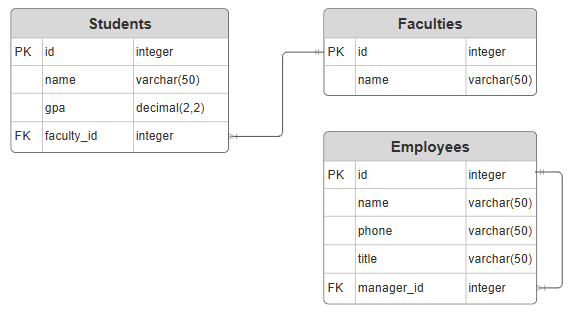

## Оператор WITH

In [8]:
%%sql
WITH g AS
(
SELECT faculty_id, min(gpa) as min_gpa
    FROM Students
 GROUP
    BY faculty_id
)
SELECT s.*
    FROM Students s
INNER JOIN g
    ON s.faculty_id = g.faculty_id
WHERE s.gpa > g.min_gpa;

 * sqlite://
Done.


id,name,gpa,faculty_id
3,Verikov,4,1
4,Smith,4.2,2
5,Lee,4.5,1


In [9]:
%%sql
SELECT * FROM g;

 * sqlite://
(sqlite3.OperationalError) no such table: g
[SQL: SELECT * FROM g;]
(Background on this error at: https://sqlalche.me/e/21/e3q8)


In [10]:
%%sql
WITH KIB_fac_id AS
(
SELECT id
    FROM Faculties
WHERE name = 'KIB'
),
min_gpa as
(
SELECT MIN(gpa) as min_gpa
    FROM Students
WHERE faculty_id = (SELECT id FROM KIB_fac_id)
)
SELECT *
    FROM Students
WHERE gpa > (SELECT min_gpa from min_gpa);

 * sqlite://
Done.


id,name,gpa,faculty_id
3,Verikov,4,1
4,Smith,4.2,2
5,Lee,4.5,1


## Представления VIEW

In [11]:
%%sql
CREATE VIEW IF NOT EXISTS StudentsAndFaculties AS
SELECT s.*, f.name as faculty_name
    FROM Students s
LEFT OUTER JOIN Faculties F
    ON s.faculty_id = f.id;

 * sqlite://
Done.


[]

Представления — виртуальные таблицы, которые содержат запросы, динамически извлекающие используемые данные.

In [12]:
%%sql
SELECT * FROM StudentsAndFaculties;

 * sqlite://
Done.


id,name,gpa,faculty_id,faculty_name
1,Sidorov,3,1,IT
2,Petrov,3.5,2,KIB
3,Verikov,4,1,IT
4,Smith,4.2,2,KIB
5,Lee,4.5,1,IT
6,Vorontsov,3.2,None,None


In [13]:
%%sql

PRAGMA foreign_keys = OFF;
DROP TABLE Faculties;

 * sqlite://
Done.
Done.


[]

In [14]:
%%sql
SELECT * FROM StudentsAndFaculties;

 * sqlite://
(sqlite3.OperationalError) no such table: main.Faculties
[SQL: SELECT * FROM StudentsAndFaculties;]
(Background on this error at: https://sqlalche.me/e/21/e3q8)


## CASE WHEN

In [15]:
%%sql
SELECT *,
    CASE WHEN gpa > 4.0
              THEN 'A'
            WHEN gpa > 3.0
              THEN 'B'
            ELSE 'C'
    END as mark
    FROM Students;

 * sqlite://
Done.


id,name,gpa,faculty_id,mark
1,Sidorov,3,1,C
2,Petrov,3.5,2,B
3,Verikov,4,1,B
4,Smith,4.2,2,A
5,Lee,4.5,1,A
6,Vorontsov,3.2,None,B


In [16]:
%%sql
SELECT Students.*,
       CASE WHEN gpa > 4.0
              THEN 'A'
            WHEN gpa > 3.0
              THEN 'B'
            ELSE 'C'
       END as mark
    FROM Students;

 * sqlite://
Done.


id,name,gpa,faculty_id,mark
1,Sidorov,3,1,C
2,Petrov,3.5,2,B
3,Verikov,4,1,B
4,Smith,4.2,2,A
5,Lee,4.5,1,A
6,Vorontsov,3.2,None,B


In [17]:
%%sql
SELECT mark, count(*) FROM
    (SELECT CASE WHEN gpa > 4.0
                  THEN 'A'
                WHEN gpa > 3.0
                  THEN 'B'
                ELSE 'C'
            END as mark
        FROM Students) as c
GROUP BY c.mark;

 * sqlite://
Done.


mark,count(*)
A,2
B,3
C,1


## Рекурсивные запросы

In [18]:
%%sql
WITH RECURSIVE cnt(x) AS (
    VALUES(1)

    UNION ALL

    SELECT x+1 FROM cnt
    WHERE x < 10
    )
SELECT x FROM cnt;

 * sqlite://
Done.


x
1
2
3
4
5
6
7
8
9
10


In [19]:
%%sql
select * from Employees;

 * sqlite://
Done.


id,name,phone,title,manager_id
1,Vasyugin,+111,Director,None
2,Jones,+112,Vice President,1
3,Smith,+113,Vice President,1
4,Velaskes,+114,Developer,2
5,Simon,+115,Analyst,2
6,Johnson,+116,Engineer,3
7,Lee,+117,Engineer,3


In [20]:
%%sql
WITH recursive ManagerPath(title_path, manager_id) AS (
    SELECT title as title_path, id as manager_id
        FROM Employees
    WHERE manager_id is null

    UNION

    SELECT ManagerPath.title_path || '->' || Employees.title as title_path, id as manager_id
        FROM ManagerPath
    INNER JOIN Employees
    ON ManagerPath.manager_id = Employees.manager_id
    )
select *
from ManagerPath;

 * sqlite://
Done.


title_path,manager_id
Director,1
Director->Vice President,2
Director->Vice President,3
Director->Vice President->Developer,4
Director->Vice President->Analyst,5
Director->Vice President->Engineer,6
Director->Vice President->Engineer,7


In [21]:
%%sql
WITH recursive ManagerPath(title_path, manager_id, level) AS (
    SELECT title as title_path, id as manager_id, 1 as level
        FROM Employees
    WHERE manager_id is null

    UNION

    SELECT ManagerPath.title_path || '->' || Employees.title as title_path,
          id as manager_id,
          ManagerPath.level + 1 as level
    FROM ManagerPath
    INNER JOIN Employees using (manager_id)
)
select * from ManagerPath;

 * sqlite://
Done.


title_path,manager_id,level
Director,1,1
Director->Vice President,2,2
Director->Vice President,3,2
Director->Vice President->Developer,4,3
Director->Vice President->Analyst,5,3
Director->Vice President->Engineer,6,3
Director->Vice President->Engineer,7,3


In [22]:
%%sql
WITH RECURSIVE cnt(x) AS (
    VALUES(1)

    UNION ALL

    SELECT x+1 FROM cnt
    WHERE x < 5
    --WHERE x > 0  -- бесконечная рекурсия (работать не будет)
    )
SELECT x FROM cnt;

 * sqlite://
Done.


x
1
2
3
4
5


## Ограничение целостности CHECK

In [23]:
%%sql
DROP TABLE IF EXISTS Clients;

CREATE TABLE Clients(
    ID integer PRIMARY KEY,
    FirstName varchar(255) NOT NULL,
    LastName varchar(255) NOT NULL,
    Age integer,
    CHECK (Age>=18)
);

 * sqlite://
Done.
Done.


[]

In [24]:
%%sql
INSERT INTO Clients (FirstName, LastName, Age) VALUES ("Антон", "Иванов", 23);
INSERT INTO Clients (FirstName, LastName, Age) VALUES ("Андрей", "Степанов", 27);
INSERT INTO Clients (FirstName, LastName, Age) VALUES ("Наталья", "Ештукова", 20);
INSERT INTO Clients (FirstName, LastName, Age) VALUES ("Виктория", "Андреева", 37);
INSERT INTO Clients (FirstName, LastName, Age) VALUES ("Илья", "Ильин", 47);

 * sqlite://
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.
1 rows affected.


[]

In [25]:
%%sql
SELECT * FROM Clients;

 * sqlite://
Done.


ID,FirstName,LastName,Age
1,Антон,Иванов,23
2,Андрей,Степанов,27
3,Наталья,Ештукова,20
4,Виктория,Андреева,37
5,Илья,Ильин,47


In [26]:
%%sql
INSERT INTO Clients (FirstName, LastName, Age) VALUES ("Иван", "Воронцов", 17);

 * sqlite://
(sqlite3.IntegrityError) CHECK constraint failed: Age>=18
[SQL: INSERT INTO Clients (FirstName, LastName, Age) VALUES ("Иван", "Воронцов", 17);]
(Background on this error at: https://sqlalche.me/e/21/gkpj)


In [27]:
%%sql
INSERT INTO Clients (FirstName, LastName) VALUES ("Иван", "Воронцов");

 * sqlite://
1 rows affected.


[]

In [28]:
%%sql
SELECT * FROM Clients;

 * sqlite://
Done.


ID,FirstName,LastName,Age
1,Антон,Иванов,23
2,Андрей,Степанов,27
3,Наталья,Ештукова,20
4,Виктория,Андреева,37
5,Илья,Ильин,47
6,Иван,Воронцов,None


## Функции работы со строками

https://www.sqlite.org/lang_corefunc.html

The default built-in lower()/upper() function works for ASCII characters only.

In [29]:
%%sql
SELECT *, length(phone), LOWER(title), upper(name), replace(phone,'+','+7927') FROM Employees;

 * sqlite://
Done.


id,name,phone,title,manager_id,length(phone),LOWER(title),upper(name),"replace(phone,'+','+7927')"
1,Vasyugin,+111,Director,None,4,director,VASYUGIN,+7927111
2,Jones,+112,Vice President,1,4,vice president,JONES,+7927112
3,Smith,+113,Vice President,1,4,vice president,SMITH,+7927113
4,Velaskes,+114,Developer,2,4,developer,VELASKES,+7927114
5,Simon,+115,Analyst,2,4,analyst,SIMON,+7927115
6,Johnson,+116,Engineer,3,4,engineer,JOHNSON,+7927116
7,Lee,+117,Engineer,3,4,engineer,LEE,+7927117


In [30]:
%%sql
SELECT *, LOWER(FirstName) FROM Clients;

 * sqlite://
Done.


ID,FirstName,LastName,Age,LOWER(FirstName)
1,Антон,Иванов,23,Антон
2,Андрей,Степанов,27,Андрей
3,Наталья,Ештукова,20,Наталья
4,Виктория,Андреева,37,Виктория
5,Илья,Ильин,47,Илья
6,Иван,Воронцов,None,Иван


In [31]:
%%sql
SELECT *, substring(title,2), substring(name,2,5), instr(name,"e"), instr(name,"on") FROM Employees;

 * sqlite://
Done.


id,name,phone,title,manager_id,"substring(title,2)","substring(name,2,5)","instr(name,""e"")","instr(name,""on"")"
1,Vasyugin,+111,Director,None,irector,asyug,0,0
2,Jones,+112,Vice President,1,ice President,ones,4,2
3,Smith,+113,Vice President,1,ice President,mith,0,0
4,Velaskes,+114,Developer,2,eveloper,elask,2,0
5,Simon,+115,Analyst,2,nalyst,imon,0,4
6,Johnson,+116,Engineer,3,ngineer,ohnso,0,6
7,Lee,+117,Engineer,3,ngineer,ee,2,0


## Работа с временем

https://www.sqlite.org/lang_datefunc.html

In [ ]:
%%sql
SELECT date('now'), time('now');

In [ ]:
%%sql
SELECT datetime('now', 'localtime');

In [ ]:
%%sql
SELECT timediff(datetime('now'), "2000-01-01");

In [ ]:
%%sql
SELECT julianday(datetime('now'));

In [ ]:
%%sql
SELECT julianday(datetime('now')) - julianday(datetime("2000-01-01")) as diff;

In [ ]:
%%sql
SELECT datetime('now', 'start of day'), date('now','start of month'), date('now','weekday 4');

In [ ]:
%%sql
SELECT datetime('now', '+3 hours') as "Время по Москве";

In [39]:
%%sql
SELECT datetime('now','start of month','+1 month','-1 day') as "последний день месяца";

 * sqlite://
Done.


последний день месяца
2026-10-31 00:00:00


In [40]:
%%sql
SELECT julianday(datetime('now', 'start of day')) - julianday(datetime("2000-01-01")) as diff;

 * sqlite://
Done.


diff
9784.0


In [41]:
%%sql
SELECT 1
WHERE "2026-10-15" == date('now');

 * sqlite://
Done.


1
1


### strftime()

In [42]:
%%sql
SELECT strftime('%d', datetime('now'));

 * sqlite://
Done.


"strftime('%d', datetime('now'))"
15


In [ ]:
%%sql
SELECT strftime('%d-%m-%Y, time: %H:%M:%S', datetime('now'));

In [44]:
%%sql
SELECT 1
WHERE strftime('%Y', datetime('now')) == "2026";

 * sqlite://
Done.


1
1


## Математические функции

In [45]:
%%sql
DROP TABLE IF EXISTS Numbers;

CREATE TABLE Numbers(
    a integer,
    b integer
);

 * sqlite://
Done.
Done.


[]

In [46]:
%%sql
INSERT INTO Numbers VALUES (random(), 0); --между -9223372036854775808 и +9223372036854775807
INSERT INTO Numbers VALUES (random(), 0);
INSERT INTO Numbers VALUES (random(), 0);
SELECT * FROM Numbers;

 * sqlite://
1 rows affected.
1 rows affected.
1 rows affected.
Done.


a,b
-5273572960978078747,0
1991274771039565099,0
5272697201598427239,0


In [47]:
%%sql
INSERT INTO Numbers VALUES (abs(random() % 10), abs(random() % 10)); --между 0 и 10
INSERT INTO Numbers VALUES ((abs(random()) % (10-1)+1), (abs(random()) % (10-1)+1)); --между 1 и 10
INSERT INTO Numbers VALUES (NULL, NULL);
SELECT * FROM Numbers;

 * sqlite://
1 rows affected.
1 rows affected.
1 rows affected.
Done.


a,b
-5273572960978078747,0
1991274771039565099,0
5272697201598427239,0
5,8
6,8
None,None


In [48]:
%%sql
SELECT a, b, ROUND(sin(a),3), cos(a), atan(a), ROUND(sqrt(a)), ln(a), pow(a,b) FROM Numbers;

 * sqlite://
Done.


a,b,"ROUND(sin(a),3)",cos(a),atan(a),ROUND(sqrt(a)),ln(a),"pow(a,b)"
-5273572960978078747,0,0.676,0.7370888866927598,-1.5707963267948966,None,None,1.0
1991274771039565099,0,-0.453,0.8917463523626006,1.5707963267948966,1411125356.0,42.13530669600211,1.0
5272697201598427239,0,0.198,-0.980198057196356,1.5707963267948966,2296235441.0,43.109073708479485,1.0
5,8,-0.959,0.28366218546322625,1.373400766945016,2.0,1.6094379124341003,390625.0
6,8,-0.279,0.960170286650366,1.4056476493802699,2.0,1.791759469228055,1679616.0
None,None,None,None,None,None,None,None
